In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

In [6]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [7]:
import csv

df = pd.read_csv("/content/Reviews.csv", on_bad_lines='skip', escapechar='\\', quoting=csv.QUOTE_NONE)

**Data Understanding and Cleaning**

In [8]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1.0,1.0,5.0,1.303862e+09,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0.0,0.0,1.0,1.346976e+09,Not as Advertised,"""Product arrived labeled as Jumbo Salted Peanu..."
2,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3.0,3.0,2.0,1.307923e+09,Cough Medicine,If you are looking for the secret ingredient i...
3,9,B000E7L2R4,A1MZYO9TZK0BBI,R. James,1.0,1.0,5.0,1.322006e+09,Yay Barley,Right now I'm mostly just sprouting this so my...
4,10,B00171APVA,A21BT40VZCCYT4,Carol A. Reed,0.0,0.0,5.0,1.351210e+09,Healthy Dog Food,This is a very healthy dog food. Good for thei...


In [9]:
df.columns

Index(['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator',
       'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4420 entries, 0 to 4419
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Id                      4420 non-null   int64  
 1   ProductId               4420 non-null   object 
 2   UserId                  4419 non-null   object 
 3   ProfileName             4418 non-null   object 
 4   HelpfulnessNumerator    4419 non-null   float64
 5   HelpfulnessDenominator  4419 non-null   float64
 6   Score                   4419 non-null   float64
 7   Time                    4419 non-null   float64
 8   Summary                 4419 non-null   object 
 9   Text                    4419 non-null   object 
dtypes: float64(4), int64(1), object(5)
memory usage: 345.4+ KB


In [11]:
df.shape

(4420, 10)

In [12]:
df.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

In [13]:
df.describe()

,Id,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time
count,4420.000000,4419.000000,4419.000000,4419.000000,4.419000e+03
mean,8061.225339,1.033039,1.484272,4.296447,1.297463e+09
std,4701.248366,2.676338,3.747088,1.285752,4.703876e+07
min,1.000000,0.000000,0.000000,1.000000,9.617184e+08
25%,3880.500000,0.000000,0.000000,4.000000,1.274616e+09
50%,8139.000000,0.000000,0.000000,5.000000,1.311120e+09
75%,12013.750000,1.000000,2.000000,5.000000,1.332547e+09
max,16243.000000,59.000000,76.000000,5.000000,1.351210e+09


In [14]:
df.nunique()

,0
Id,4420
ProductId,1218
UserId,4136
ProfileName,4040
HelpfulnessNumerator,31
HelpfulnessDenominator,41
Score,5
Time,1532
Summary,3746
Text,4227


In [15]:
df.isnull().sum()

,0
Id,0
ProductId,0
UserId,1
ProfileName,2
HelpfulnessNumerator,1
HelpfulnessDenominator,1
Score,1
Time,1
Summary,1
Text,1


In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False)

,0
ProfileName,0.045249
UserId,0.022624
Score,0.022624
Time,0.022624
HelpfulnessNumerator,0.022624
HelpfulnessDenominator,0.022624
Summary,0.022624
Text,0.022624
ProductId,0.000000
Id,0.000000


In [17]:
df['ProfileName'] = df['ProfileName'].fillna('Unknown')
df['Summary'] = df['Summary'].fillna('')

In [18]:
df.isnull().sum()

,0
Id,0
ProductId,0
UserId,1
ProfileName,0
HelpfulnessNumerator,1
HelpfulnessDenominator,1
Score,1
Time,1
Summary,0
Text,1


In [19]:
#Remove Duplicate Records
df.duplicated().sum()

np.int64(0)

In [20]:
df = df.drop_duplicates()

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.dtypes

,0
Id,int64
ProductId,object
UserId,object
ProfileName,object
HelpfulnessNumerator,float64
HelpfulnessDenominator,float64
Score,float64
Time,float64
Summary,object
Text,object


In [23]:
#Convert Timestamp safely by turning invalid times to NaN first
df['Time'] = pd.to_numeric(df['Time'], errors='coerce')
df['ReviewDate'] = pd.to_datetime(df['Time'], unit='s', errors='coerce')

In [24]:
df[['Time', 'ReviewDate']].head()

,Time,ReviewDate
0,1.303862e+09,2011-04-27
1,1.346976e+09,2012-09-07
2,1.307923e+09,2011-06-13
3,1.322006e+09,2011-11-23
4,1.351210e+09,2012-10-26


In [25]:
df['ReviewYear'] = df['ReviewDate'].dt.year
df['ReviewMonth'] = df['ReviewDate'].dt.month

In [26]:
df['ReviewDate'].min(), df['ReviewDate'].max()

(Timestamp('2000-06-23 00:00:00'), Timestamp('2012-10-26 00:00:00'))

**Feature Engineering**

In [27]:
df['HelpfulnessNumerator'] = pd.to_numeric(df['HelpfulnessNumerator'], errors='coerce')
df['HelpfulnessDenominator'] = pd.to_numeric(df['HelpfulnessDenominator'], errors='coerce')

# Calculate Helpfulness Ratio safely
df['HelpfulnessRatio'] = np.where(
    df['HelpfulnessDenominator'] > 0,
    df['HelpfulnessNumerator'] / df['HelpfulnessDenominator'],
    0
)

In [28]:
df['HelpfulnessRatio'].describe()

,HelpfulnessRatio
count,4420.000000
mean,0.340913
std,0.448490
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [29]:
#Convert Score safely to numeric, forcing invalid strings to NaN
df['Score'] = pd.to_numeric(df['Score'], errors='coerce')

#Analyze Class Distribution
df['Score'].value_counts().sort_index()

,count
Score,
1.0,408
2.0,164
3.0,251
4.0,483
5.0,3113


In [30]:
rating_percentage = (
    df['Score'].value_counts(normalize=True)
    .sort_index() * 100
)

rating_percentage

,proportion
Score,
1.0,9.232858
2.0,3.711247
3.0,5.680018
4.0,10.930075
5.0,70.445802


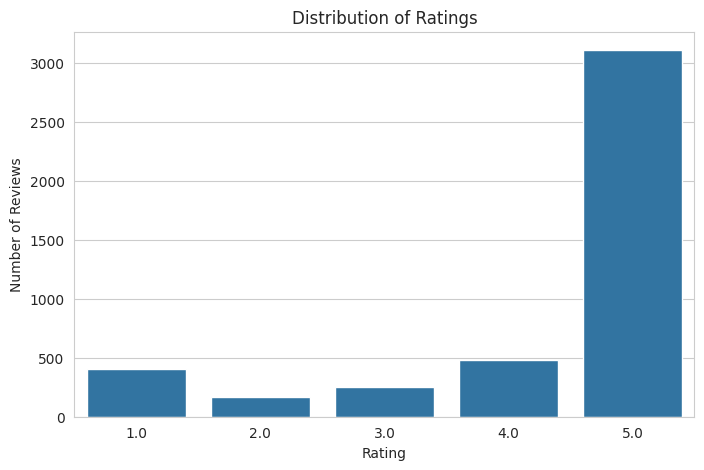

In [31]:
#Visualization: Distribution of Ratings
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='Score')

plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')

plt.show()

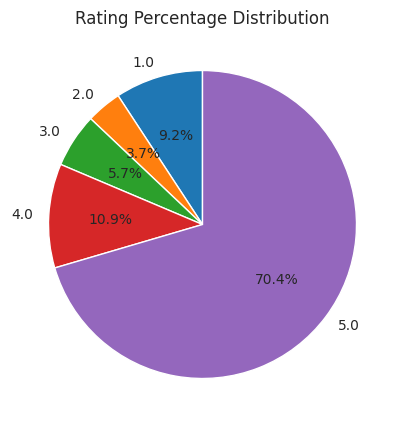

In [32]:
#Rating Percentage Distribution
plt.figure(figsize=(8,5))

plt.pie(
    rating_percentage,
    labels=rating_percentage.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Rating Percentage Distribution')

plt.show()

**Text Preprocessing**

In [33]:
df["Review"] = df["Summary"] + " " + df["Text"]

In [34]:
#Lowercase
df['CleanText'] = df['Review'].str.lower()

In [35]:
df[['Review', 'CleanText']].head()

,Review,CleanText
0,Good Quality Dog Food I have bought several of...,good quality dog food i have bought several of...
1,"Not as Advertised ""Product arrived labeled as ...","not as advertised ""product arrived labeled as ..."
2,Cough Medicine If you are looking for the secr...,cough medicine if you are looking for the secr...
3,Yay Barley Right now I'm mostly just sprouting...,yay barley right now i'm mostly just sprouting...
4,Healthy Dog Food This is a very healthy dog fo...,healthy dog food this is a very healthy dog fo...


In [36]:
#Remove HTML Tags
def remove_html(Review):
    if not isinstance(Review, str):
        return ""
    return re.sub(r'<.*?>', '', Review)

df['CleanText'] = df['CleanText'].astype(str).apply(remove_html)

In [37]:
#Remove URLs
def remove_urls(Review):
    return re.sub(r'http\S+|www\S+|https\S+', '', Review)

df['CleanText'] = df['CleanText'].apply(remove_urls)

In [38]:
#Remove Punctuation
def remove_punctuation(Review):
    return Review.translate(str.maketrans('', '', string.punctuation))

df['CleanText'] = df['CleanText'].apply(remove_punctuation)

In [39]:
#Remove Extra Spaces
df['CleanText'] = df['CleanText'].str.replace(r'\s+', ' ', regex=True).str.strip()

In [40]:
#Remove Stopwords
stop_words = set(stopwords.words('english'))

In [41]:
def remove_stopwords(Review):
    words = Review.split()
    words = [word for word in words if word not in stop_words]
    return ' '.join(words)

df['CleanText'] = df['CleanText'].apply(remove_stopwords)

In [42]:
#Tokenization
from nltk.tokenize import word_tokenize

df['Tokens'] = df['CleanText'].apply(word_tokenize)

In [43]:
df[['CleanText', 'Tokens']].head()

,CleanText,Tokens
0,good quality dog food bought several vitality ...,"[good, quality, dog, food, bought, several, vi..."
1,advertised product arrived labeled jumbo salte...,"[advertised, product, arrived, labeled, jumbo,..."
2,cough medicine looking secret ingredient robit...,"[cough, medicine, looking, secret, ingredient,..."
3,yay barley right im mostly sprouting cats eat ...,"[yay, barley, right, im, mostly, sprouting, ca..."
4,healthy dog food healthy dog food good digesti...,"[healthy, dog, food, healthy, dog, food, good,..."


In [44]:
#Lemmatization
lemmatizer = WordNetLemmatizer()

def lemmatize_text(tokens):
    return [lemmatizer.lemmatize(word) for word in tokens]

df['LemmatizedTokens'] = df['Tokens'].apply(lemmatize_text)

In [45]:
df['ProcessedText'] = df['LemmatizedTokens'].apply(lambda x: ' '.join(x))

In [46]:
df[['Review', 'ProcessedText']].head()

,Review,ProcessedText
0,Good Quality Dog Food I have bought several of...,good quality dog food bought several vitality ...
1,"Not as Advertised ""Product arrived labeled as ...",advertised product arrived labeled jumbo salte...
2,Cough Medicine If you are looking for the secr...,cough medicine looking secret ingredient robit...
3,Yay Barley Right now I'm mostly just sprouting...,yay barley right im mostly sprouting cat eat g...
4,Healthy Dog Food This is a very healthy dog fo...,healthy dog food healthy dog food good digesti...


**EDA**

In [47]:
#Review Length
df['ReviewLength'] = df['ProcessedText'].str.split().str.len()

In [48]:
df['ReviewLength'].describe()

,ReviewLength
count,4420.000000
mean,23.065611
std,13.253196
min,1.000000
25%,15.000000
50%,19.000000
75%,27.000000
max,226.000000


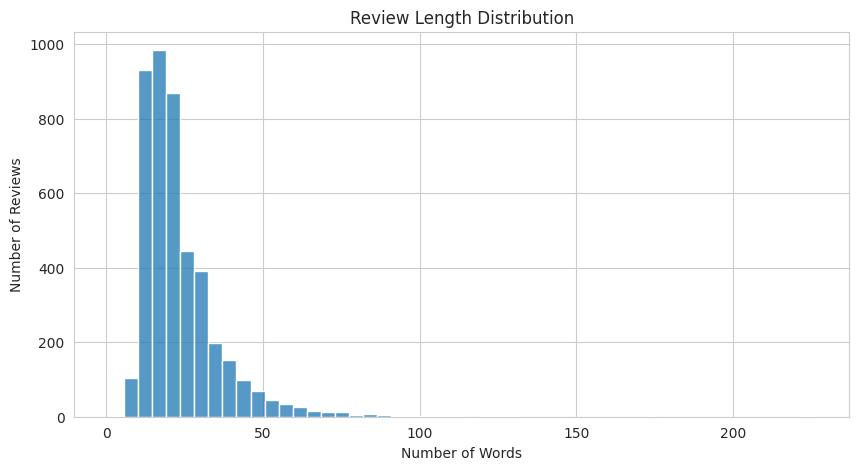

In [49]:
#Review Length Distribution
plt.figure(figsize=(10,5))

sns.histplot(
    df['ReviewLength'],
    bins=50
)

plt.title('Review Length Distribution')
plt.xlabel('Number of Words')
plt.ylabel('Number of Reviews')

plt.show()

In [50]:
#Average Review Length by Rating
avg_length_rating = df.groupby('Score')['ReviewLength'].mean()

avg_length_rating

,ReviewLength
Score,
1.0,25.950980
2.0,24.713415
3.0,25.374502
4.0,23.910973
5.0,22.290395


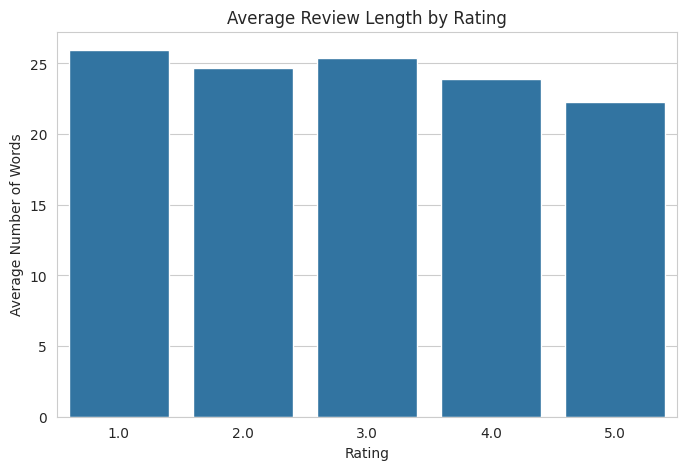

In [51]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=avg_length_rating.index,
    y=avg_length_rating.values
)

plt.title('Average Review Length by Rating')
plt.xlabel('Rating')
plt.ylabel('Average Number of Words')

plt.show()

In [52]:
#Most Frequent Words
positive_reviews = df[df['Score'].isin([4, 5])]

In [53]:
positive_text = ' '.join(positive_reviews['ProcessedText'])

In [54]:
positive_words = positive_text.split()

positive_word_counts = Counter(positive_words)

positive_word_counts.most_common(20)

[('great', 1733),
 ('love', 1260),
 ('good', 1237),
 ('coffee', 1058),
 ('product', 913),
 ('like', 800),
 ('taste', 795),
 ('best', 792),
 ('flavor', 761),
 ('one', 611),
 ('tea', 562),
 ('dog', 537),
 ('price', 459),
 ('make', 456),
 ('get', 412),
 ('food', 409),
 ('treat', 405),
 ('time', 397),
 ('really', 388),
 ('would', 388)]

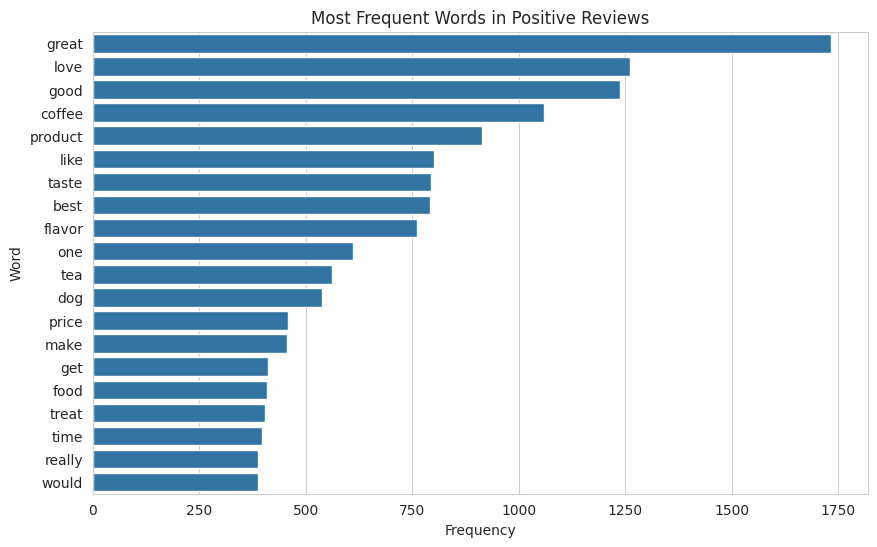

In [55]:
#Plot Top Positive Words
top_positive = pd.DataFrame(
    positive_word_counts.most_common(20),
    columns=['Word', 'Count']
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_positive,
    x='Count',
    y='Word'
)

plt.title('Most Frequent Words in Positive Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')

plt.show()

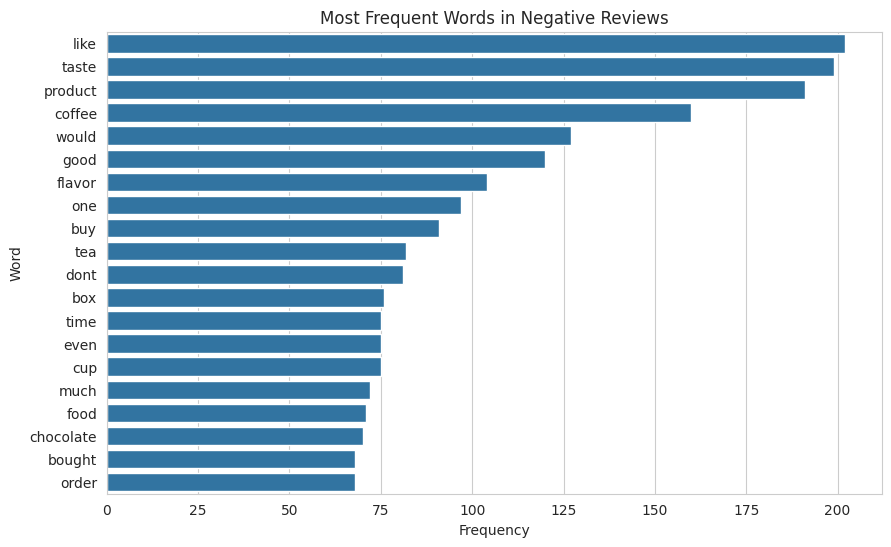

In [56]:
# Filter for negative reviews (ratings 1 and 2)
negative_reviews = df[df['Score'].isin([1, 2])]
negative_text = ' '.join(negative_reviews['ProcessedText'].astype(str))
negative_words = negative_text.split()
negative_word_counts = Counter(negative_words)

#Plot Top Negative Words
top_negative = pd.DataFrame(
    negative_word_counts.most_common(20),
    columns=['Word', 'Count']
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_negative,
    x='Count',
    y='Word'
)

plt.title('Most Frequent Words in Negative Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')

plt.show()

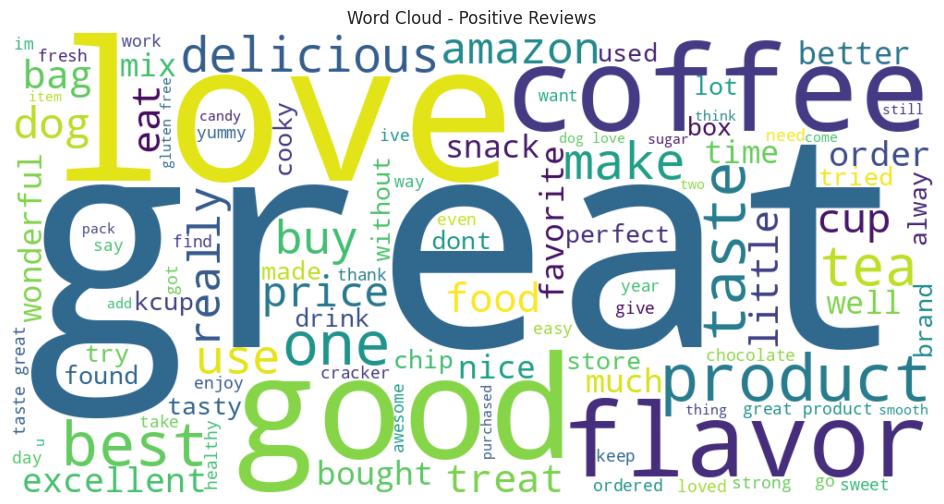

In [57]:
#Word Cloud: Positive Reviews
wordcloud_positive = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(positive_text)

plt.figure(figsize=(12,6))

plt.imshow(wordcloud_positive, interpolation='bilinear')

plt.axis('off')
plt.title('Word Cloud - Positive Reviews')

plt.show()

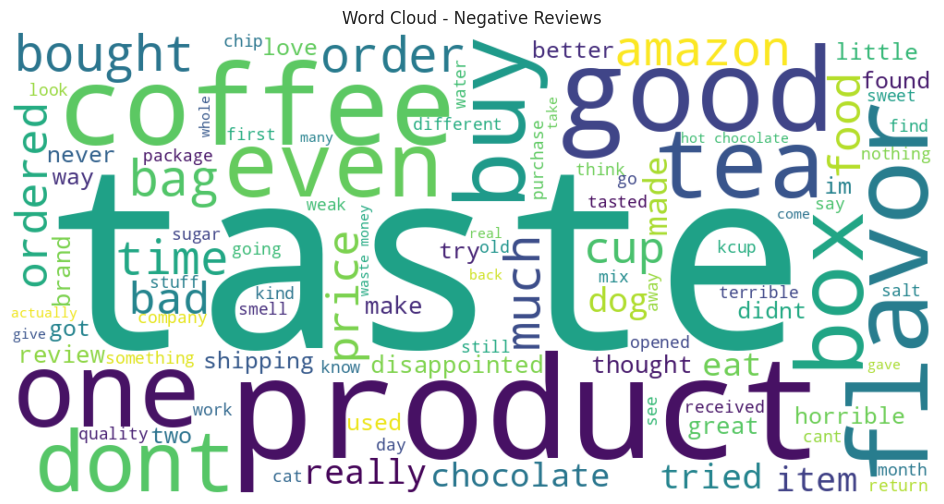

In [58]:
#Word Cloud: Negative Reviews
wordcloud_negative = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(negative_text)

plt.figure(figsize=(12,6))

plt.imshow(wordcloud_negative, interpolation='bilinear')

plt.axis('off')
plt.title('Word Cloud - Negative Reviews')

plt.show()

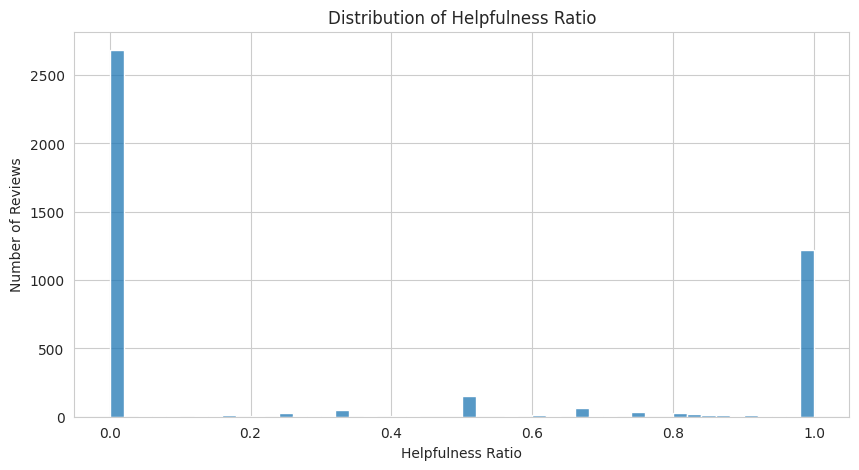

In [59]:
#Helpfulness Ratio Distribution
plt.figure(figsize=(10,5))

sns.histplot(
    df['HelpfulnessRatio'],
    bins=50
)

plt.title('Distribution of Helpfulness Ratio')
plt.xlabel('Helpfulness Ratio')
plt.ylabel('Number of Reviews')

plt.show()

In [60]:
#Rating vs Helpfulness
helpfulness_by_rating = df.groupby('Score')['HelpfulnessRatio'].mean()

helpfulness_by_rating

,HelpfulnessRatio
Score,
1.0,0.333806
2.0,0.296307
3.0,0.310322
4.0,0.357774
5.0,0.344154


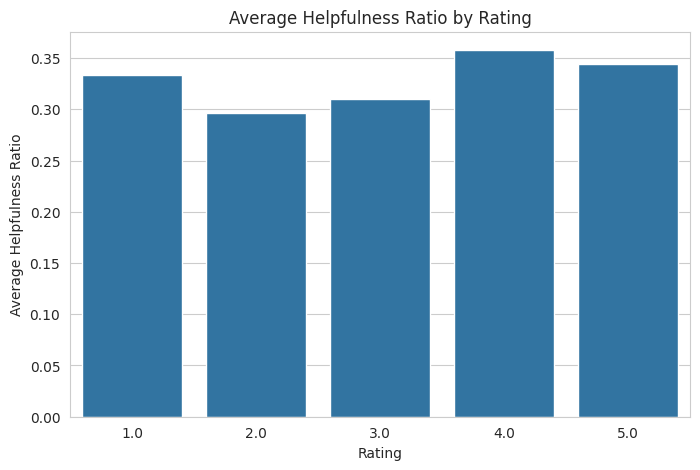

In [61]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=helpfulness_by_rating.index,
    y=helpfulness_by_rating.values
)

plt.title('Average Helpfulness Ratio by Rating')
plt.xlabel('Rating')
plt.ylabel('Average Helpfulness Ratio')

plt.show()

In [62]:
#Top Reviewed Products
top_products = df['ProductId'].value_counts().head(10)

top_products

,count
ProductId,
B006N3IG4K,148
B003VXFK44,148
B005K4Q1VI,120
B001RVFDOO,101
B003EML8PM,86
B004K30HO2,71
B004391DK0,64
B000255OIG,62
B007TJGZ5E,58


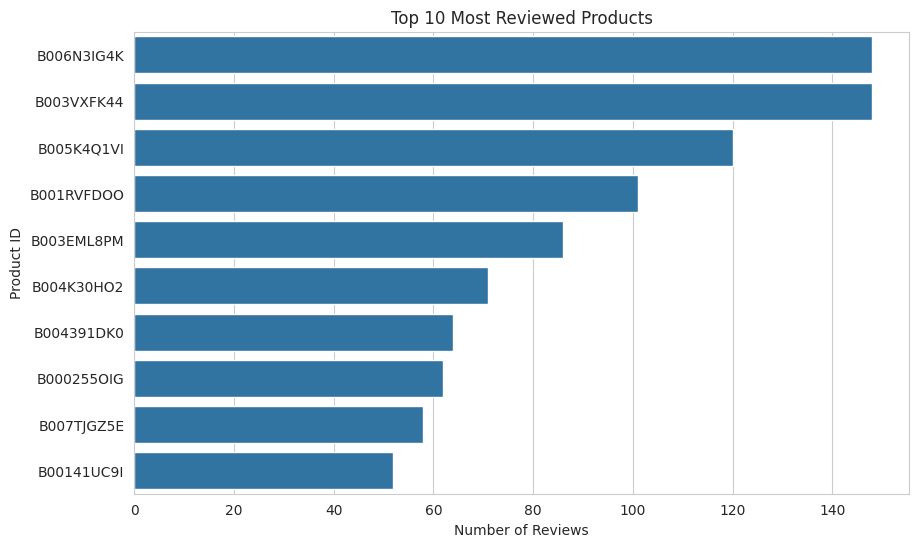

In [63]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title('Top 10 Most Reviewed Products')
plt.xlabel('Number of Reviews')
plt.ylabel('Product ID')

plt.show()

In [64]:
#Top Active Users
top_users = df['UserId'].value_counts().head(10)

top_users

,count
UserId,
AZV26LP92E6WU,4
A1ZZMAVRCBL357,4
A2H74FIBDN5NMR,4
A2A8KWCE8RKB9T,4
A3TX6CWSZL02PW,4
A1Q3VZH3TP8DFN,3
A1NASHF2NH7WV9,3
A2HKU4SOT0CWG9,3
A1IC75BCAGQ4IK,3


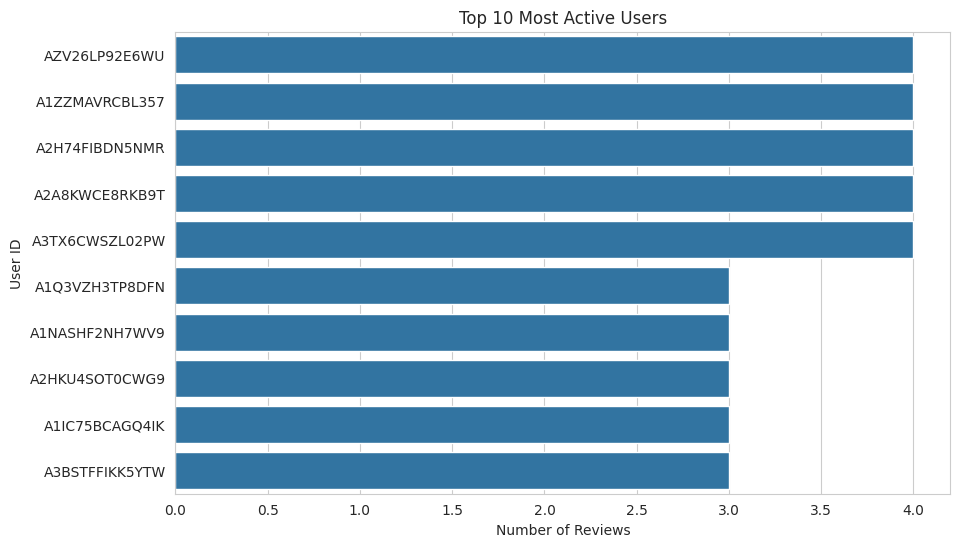

In [65]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=top_users.values,
    y=top_users.index
)

plt.title('Top 10 Most Active Users')
plt.xlabel('Number of Reviews')
plt.ylabel('User ID')

plt.show()

In [66]:
#Most Common Review Words
all_text = ' '.join(df['ProcessedText'])

all_words = all_text.split()

word_counts = Counter(all_words)

word_counts.most_common(20)

[('great', 1810),
 ('good', 1457),
 ('love', 1321),
 ('coffee', 1317),
 ('product', 1167),
 ('like', 1095),
 ('taste', 1065),
 ('flavor', 934),
 ('best', 820),
 ('one', 754),
 ('tea', 684),
 ('dog', 606),
 ('would', 562),
 ('price', 530),
 ('make', 521),
 ('get', 509),
 ('food', 498),
 ('time', 498),
 ('buy', 480),
 ('really', 472)]

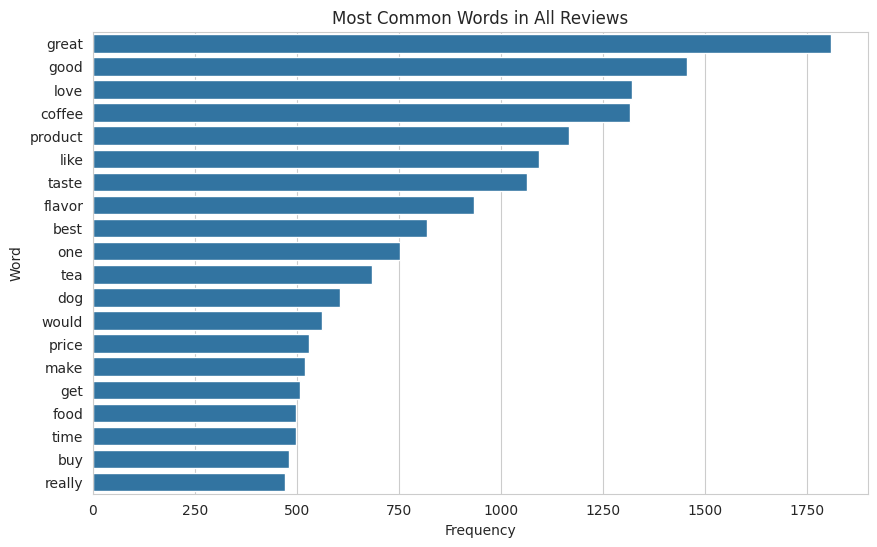

In [67]:
top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=['Word', 'Count']
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_words,
    x='Count',
    y='Word'
)

plt.title('Most Common Words in All Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')

plt.show()

**Outlier Detection**

In [68]:
numerical_features = [
    'HelpfulnessNumerator',
    'HelpfulnessDenominator',
    'HelpfulnessRatio',
    'ReviewLength'
]

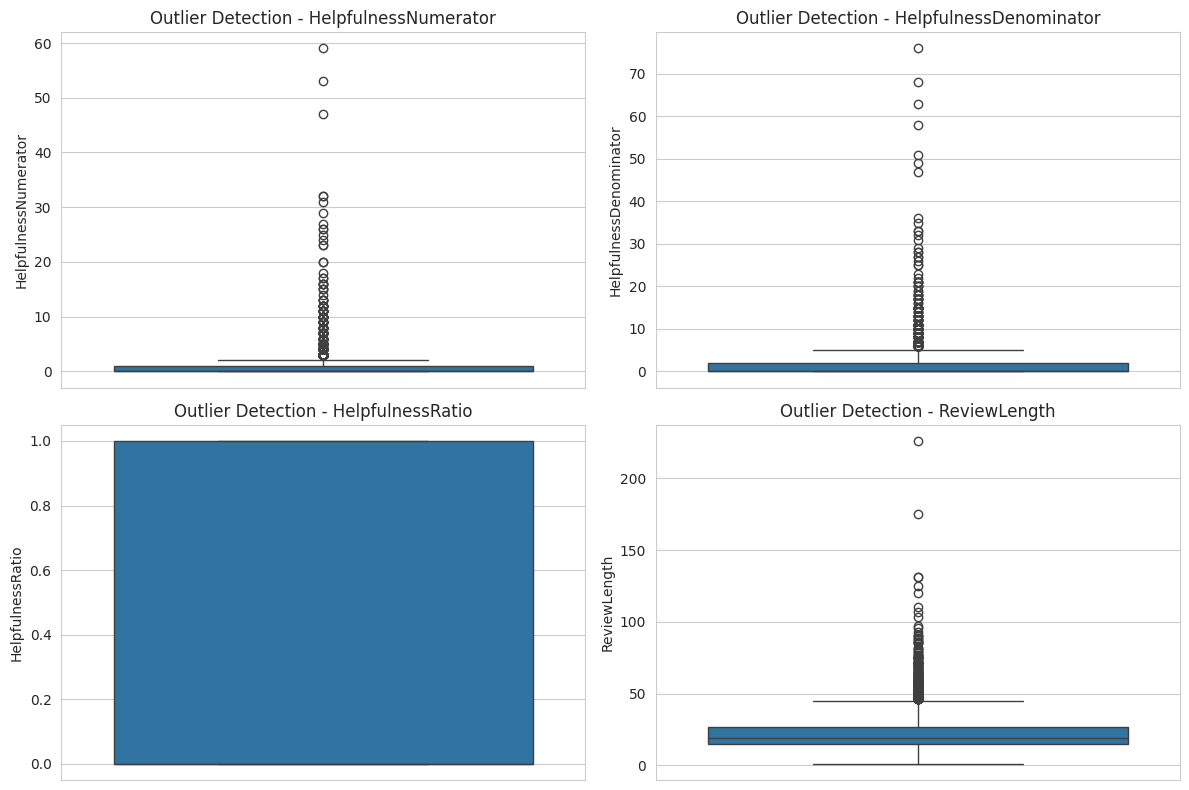

In [69]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f'Outlier Detection - {col}')

plt.tight_layout()
plt.show()

**Text Classification**

In [70]:
X = df['CleanText']
y = df['Score']

In [71]:
from sklearn.model_selection import train_test_split

# Drop rows where Score is NaN or has less than 2 members in the dataset
non_nan_indices = y.notna()
X_cleaned = X[non_nan_indices]
y_cleaned = y[non_nan_indices]

# Filter out extremely rare classes with only 1 member
class_counts = y_cleaned.value_counts()
valid_classes = class_counts[class_counts >= 2].index

filter_mask = y_cleaned.isin(valid_classes)
X_final = X_cleaned[filter_mask]
y_final = y_cleaned[filter_mask]

X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    random_state=42,
    stratify=y_final
)

In [72]:
print("Training data:", X_text_train.shape)
print("Testing data:", X_text_test.shape)

Training data: (3535,)
Testing data: (884,)


**Bag of Words**

In [73]:
from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer(
    max_features=10000,
    ngram_range=(1, 1)
)

X_train_bow = bow.fit_transform(X_text_train)
X_test_bow = bow.transform(X_text_test)

print("X_train_bow shape:", X_train_bow.shape)
print("X_test_bow shape:", X_test_bow.shape)

X_train_bow shape: (3535, 9396)
X_test_bow shape: (884, 9396)


In [74]:
print(bow.get_feature_names_out()[:20])

['01g' '041' '057' '060cup' '08' '099ea' '0z' '10' '100' '1000' '1000mg'
 '1000s' '1015' '1020' '102012' '10860' '1099' '10am' '10first' '10lbs']


**Tf-IDF**

In [75]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 1)
)

X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

print("X_train_tfidf shape:", X_train_tfidf.shape)
print("X_test_tfidf shape:", X_test_tfidf.shape)

X_train_tfidf shape: (3535, 9396)
X_test_tfidf shape: (884, 9396)


**Naive Bayes with BOW**

In [76]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

nb_bow = MultinomialNB()
nb_bow.fit(X_train_bow, y_text_train)
y_pred_nb_bow = nb_bow.predict(X_test_bow)

print("Naive Bayes + BoW Accuracy:", accuracy_score(y_text_test, y_pred_nb_bow))
print(classification_report(y_text_test, y_pred_nb_bow))

Naive Bayes + BoW Accuracy: 0.7420814479638009
              precision    recall  f1-score   support

         1.0       0.91      0.40      0.55        81
         2.0       0.67      0.06      0.11        33
         3.0       0.33      0.02      0.04        50
         4.0       0.38      0.05      0.09        97
         5.0       0.74      0.99      0.85       623

    accuracy                           0.74       884
   macro avg       0.61      0.30      0.33       884
weighted avg       0.69      0.74      0.66       884



In [77]:
nb_tfidf = MultinomialNB()
nb_tfidf.fit(X_train_tfidf, y_text_train)
y_pred_nb_tfidf = nb_tfidf.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_text_test, y_pred_nb_tfidf))
print("\nClassification Report:")
print(classification_report(y_text_test, y_pred_nb_tfidf))

Accuracy: 0.7047511312217195

Classification Report:
              precision    recall  f1-score   support

         1.0       0.00      0.00      0.00        81
         2.0       0.00      0.00      0.00        33
         3.0       0.00      0.00      0.00        50
         4.0       0.00      0.00      0.00        97
         5.0       0.70      1.00      0.83       623

    accuracy                           0.70       884
   macro avg       0.14      0.20      0.17       884
weighted avg       0.50      0.70      0.58       884



**Logistic Regression **

In [78]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_bow = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_bow.fit(X_train_bow, y_text_train)
y_pred_lr_bow = lr_bow.predict(X_test_bow)

print("Logistic Regression - BoW")
print("Accuracy:", accuracy_score(y_text_test, y_pred_lr_bow))
print("\nClassification Report:")
print(classification_report(y_text_test, y_pred_lr_bow))

Logistic Regression - BoW
Accuracy: 0.7613122171945701

Classification Report:
              precision    recall  f1-score   support

         1.0       0.78      0.56      0.65        81
         2.0       0.43      0.18      0.26        33
         3.0       0.56      0.28      0.37        50
         4.0       0.29      0.18      0.22        97
         5.0       0.81      0.95      0.87       623

    accuracy                           0.76       884
   macro avg       0.57      0.43      0.47       884
weighted avg       0.72      0.76      0.73       884



In [79]:
lr_tfidf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_tfidf.fit(X_train_tfidf, y_text_train)
y_pred_lr_tfidf = lr_tfidf.predict(X_test_tfidf)

print("Logistic Regression - TF-IDF")
print("Accuracy:", accuracy_score(y_text_test, y_pred_lr_tfidf))
print("\nClassification Report:")
print(classification_report(y_text_test, y_pred_lr_tfidf))

Logistic Regression - TF-IDF
Accuracy: 0.7352941176470589

Classification Report:
              precision    recall  f1-score   support

         1.0       0.87      0.25      0.38        81
         2.0       1.00      0.03      0.06        33
         3.0       1.00      0.04      0.08        50
         4.0       0.50      0.04      0.08        97
         5.0       0.73      1.00      0.85       623

    accuracy                           0.74       884
   macro avg       0.82      0.27      0.29       884
weighted avg       0.74      0.74      0.65       884



**SVM**

In [80]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

svm_bow = LinearSVC(random_state=42)
svm_bow.fit(X_train_bow, y_text_train)
y_pred_svm_bow = svm_bow.predict(X_test_bow)

print("SVM - BoW")
print("Accuracy:", accuracy_score(y_text_test, y_pred_svm_bow))
print("\nClassification Report:")
print(classification_report(y_text_test, y_pred_svm_bow))

SVM - BoW
Accuracy: 0.7398190045248869

Classification Report:
              precision    recall  f1-score   support

         1.0       0.78      0.48      0.60        81
         2.0       0.28      0.21      0.24        33
         3.0       0.47      0.30      0.37        50
         4.0       0.29      0.28      0.29        97
         5.0       0.83      0.91      0.87       623

    accuracy                           0.74       884
   macro avg       0.53      0.44      0.47       884
weighted avg       0.72      0.74      0.73       884



In [81]:
svm_tfidf = LinearSVC(random_state=42)
svm_tfidf.fit(X_train_tfidf, y_text_train)
y_pred_svm_tfidf = svm_tfidf.predict(X_test_tfidf)

print("SVM - TF-IDF")
print("Accuracy:", accuracy_score(y_text_test, y_pred_svm_tfidf))
print("\nClassification Report:")
print(classification_report(y_text_test, y_pred_svm_tfidf))

SVM - TF-IDF
Accuracy: 0.7782805429864253

Classification Report:
              precision    recall  f1-score   support

         1.0       0.81      0.57      0.67        81
         2.0       0.67      0.18      0.29        33
         3.0       0.59      0.32      0.42        50
         4.0       0.40      0.18      0.24        97
         5.0       0.81      0.97      0.88       623

    accuracy                           0.78       884
   macro avg       0.65      0.44      0.50       884
weighted avg       0.74      0.78      0.74       884



In [82]:
from sklearn.metrics import accuracy_score

try:
    if 'y_pred_svm_bow' not in globals() or len(y_pred_svm_bow) != len(y_text_test):
        print("Recalculating predictions for SVM - BoW...")
        svm_bow.fit(X_train_bow, y_text_train)
        y_pred_svm_bow = svm_bow.predict(X_test_bow)

    if 'y_pred_svm_tfidf' not in globals() or len(y_pred_svm_tfidf) != len(y_text_test):
        print("Recalculating predictions for SVM - TF-IDF...")
        svm_tfidf.fit(X_train_tfidf, y_text_train)
        y_pred_svm_tfidf = svm_tfidf.predict(X_test_tfidf)

    print("SVM - BoW Accuracy:", accuracy_score(y_text_test, y_pred_svm_bow))
    print("SVM - TF-IDF Accuracy:", accuracy_score(y_text_test, y_pred_svm_tfidf))
except Exception as e:
    print("Error calculating accuracy:", e)

SVM - BoW Accuracy: 0.7398190045248869
SVM - TF-IDF Accuracy: 0.7782805429864253


In [84]:
from sklearn.model_selection import train_test_split

# Take a smaller sample from training data (3535 samples available)
X_train_small, _, y_train_small, _ = train_test_split(
    X_text_train,
    y_text_train,
    train_size=2000,
    random_state=42,
    stratify=y_text_train
)

# Take a smaller sample from testing data (884 samples available)
X_test_small, _, y_test_small, _ = train_test_split(
    X_text_test,
    y_text_test,
    train_size=500,
    random_state=42,
    stratify=y_text_test
)

# Transform using the existing TF-IDF vectorizer
X_train_small_tfidf = tfidf.transform(X_train_small)
X_test_small_tfidf = tfidf.transform(X_test_small)

print(X_train_small_tfidf.shape)
print(X_test_small_tfidf.shape)

(2000, 9396)
(500, 9396)


In [85]:
#decision tree classifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(
    max_depth=30,
    random_state=42
)

dt_model.fit(X_train_small_tfidf, y_train_small)

y_pred_dt = dt_model.predict(X_test_small_tfidf)

print("Decision Tree Accuracy:",
      accuracy_score(y_test_small, y_pred_dt))

print("\nClassification Report:")
print(classification_report(
    y_test_small,
    y_pred_dt,
    zero_division=0
))

Decision Tree Accuracy: 0.658

Classification Report:
              precision    recall  f1-score   support

         1.0       0.50      0.13      0.21        46
         2.0       0.14      0.05      0.08        19
         3.0       0.20      0.07      0.11        28
         4.0       0.15      0.11      0.12        55
         5.0       0.73      0.89      0.80       352

    accuracy                           0.66       500
   macro avg       0.34      0.25      0.26       500
weighted avg       0.59      0.66      0.61       500



In [86]:
#randomforest classifier
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=30,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_small_tfidf, y_train_small)

y_pred_rf = rf_model.predict(X_test_small_tfidf)

print("Random Forest Accuracy:",
      accuracy_score(y_test_small, y_pred_rf))

print("\nClassification Report:")
print(classification_report(
    y_test_small,
    y_pred_rf,
    zero_division=0
))

Random Forest Accuracy: 0.706

Classification Report:
              precision    recall  f1-score   support

         1.0       1.00      0.02      0.04        46
         2.0       0.00      0.00      0.00        19
         3.0       0.00      0.00      0.00        28
         4.0       0.00      0.00      0.00        55
         5.0       0.71      1.00      0.83       352

    accuracy                           0.71       500
   macro avg       0.34      0.20      0.17       500
weighted avg       0.59      0.71      0.59       500



In [87]:
#k-nearest neighbour
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='cosine',
    algorithm='brute'
)

knn_model.fit(X_train_small_tfidf, y_train_small)

y_pred_knn = knn_model.predict(X_test_small_tfidf)

print("KNN Accuracy:",
      accuracy_score(y_test_small, y_pred_knn))

print("\nClassification Report:")
print(classification_report(
    y_test_small,
    y_pred_knn,
    zero_division=0
))

KNN Accuracy: 0.69

Classification Report:
              precision    recall  f1-score   support

         1.0       0.55      0.24      0.33        46
         2.0       0.12      0.05      0.07        19
         3.0       0.00      0.00      0.00        28
         4.0       0.14      0.07      0.10        55
         5.0       0.74      0.93      0.83       352

    accuracy                           0.69       500
   macro avg       0.31      0.26      0.27       500
weighted avg       0.59      0.69      0.63       500



In [88]:
#compare all machine learning method
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "SVM": LinearSVC(random_state=42),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=30, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=30,
        random_state=42,
        n_jobs=-1
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric='cosine',
        algorithm='brute'
    )
}

results = []

for name, model in models.items():

    model.fit(X_train_small_tfidf, y_train_small)

    y_pred = model.predict(X_test_small_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_small, y_pred),
        "Precision": precision_score(
            y_test_small, y_pred,
            average='weighted', zero_division=0
        ),
        "Recall": recall_score(
            y_test_small, y_pred,
            average='weighted', zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_small, y_pred,
            average='weighted', zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
2,SVM,0.744,0.683261,0.744,0.688555
5,KNN,0.690,0.592722,0.690,0.626034
3,Decision Tree,0.658,0.592810,0.658,0.606963
1,Logistic Regression,0.714,0.669320,0.714,0.605386
4,Random Forest,0.706,0.588609,0.706,0.586307
0,Naive Bayes,0.704,0.495616,0.704,0.581709


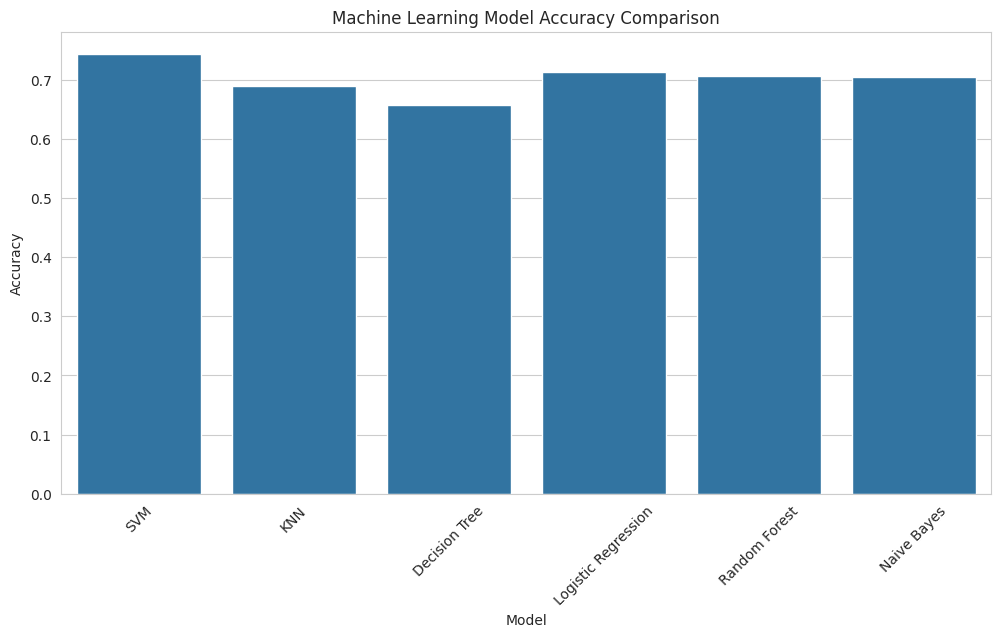

In [89]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xticks(rotation=45)
plt.show()

Best Model: SVM


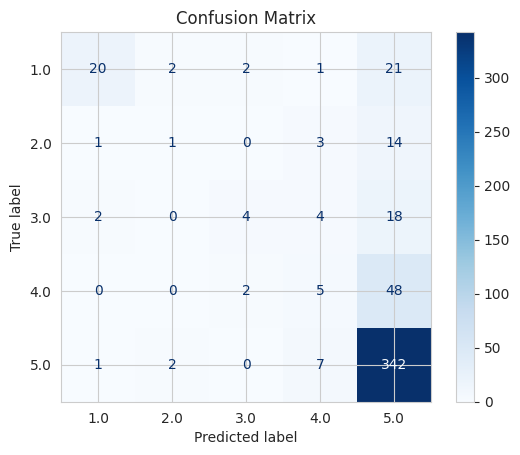

In [90]:
#confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model_name = results_df.iloc[0]['Model']

print("Best Model:", best_model_name)

best_model = models[best_model_name]

y_pred_best = best_model.predict(X_test_small_tfidf)

cm = confusion_matrix(y_test_small, y_pred_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sorted(y_test_small.unique())
)

disp.plot(cmap='Blues')

plt.title("Confusion Matrix")
plt.show()

**Sprint-3**

In [91]:
#hyperparameter tuning
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC

svm = LinearSVC(random_state=42)

param_grid = {
    'C': [0.1, 0.5, 1, 2, 5]
}

grid_search = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train_small_tfidf,
    y_train_small
)

print("Best Parameters:", grid_search.best_params_)

print("Best CV Score:", grid_search.best_score_)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Parameters: {'C': 5}
Best CV Score: 0.6853125215596608


In [92]:
#evaluate the tuned model
best_svm = grid_search.best_estimator_

y_pred_tuned = best_svm.predict(X_test_small_tfidf)

print("Tuned SVM Accuracy:",
      accuracy_score(y_test_small, y_pred_tuned))

print("\nClassification Report:")

print(classification_report(
    y_test_small,
    y_pred_tuned,
    zero_division=0
))

Tuned SVM Accuracy: 0.732

Classification Report:
              precision    recall  f1-score   support

         1.0       0.70      0.46      0.55        46
         2.0       0.25      0.11      0.15        19
         3.0       0.56      0.18      0.27        28
         4.0       0.21      0.15      0.17        55
         5.0       0.80      0.94      0.86       352

    accuracy                           0.73       500
   macro avg       0.50      0.36      0.40       500
weighted avg       0.69      0.73      0.70       500



In [93]:
#compare baseline and tuned model
baseline_svm = LinearSVC(random_state=42)

baseline_svm.fit(
    X_train_small_tfidf,
    y_train_small
)

baseline_pred = baseline_svm.predict(
    X_test_small_tfidf
)

baseline_accuracy = accuracy_score(
    y_test_small, baseline_pred
)

tuned_accuracy = accuracy_score(
    y_test_small, y_pred_tuned
)

comparison = pd.DataFrame({
    'Model': ['Baseline SVM', 'Tuned SVM'],
    'Accuracy': [baseline_accuracy, tuned_accuracy]
})

print(comparison)

          Model  Accuracy
0  Baseline SVM     0.744
1     Tuned SVM     0.732


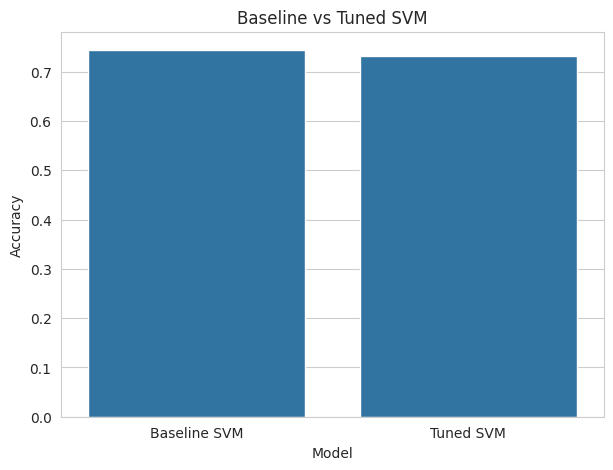

In [94]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=comparison,
    x='Model',
    y='Accuracy'
)

plt.title("Baseline vs Tuned SVM")
plt.show()

In [95]:
#feature importance
feature_names = tfidf.get_feature_names_out()

coefficients = best_svm.coef_

classes = best_svm.classes_

for i, rating in enumerate(classes):

    top_indices = np.argsort(coefficients[i])[-15:]

    top_words = feature_names[top_indices]

    print(f"\nImportant words for Rating {rating}:")

    print(top_words[::-1])


Important words for Rating 1.0:
['horrible' 'terrible' 'usei' 'return' 'worst' 'unpleasant' 'smell'
 'doubled' 'money' 'mushy' 'china' 'sick' 'tasted' 'crumbly' 'version']

Important words for Rating 2.0:
['nestle' 'weak' 'bland' 'escapes' 'trashcan' 'jam' 'herbal' 'way' 'stuck'
 'vinegary' 'marzipan' 'lab' 'listened' 'sorry' 'pocky']

Important words for Rating 3.0:
['watery' 'ok' 'okay' 'expecting' 'flecks' 'thin' 'connosieur' 'supposed'
 'opinions' 'ones' 'mini' 'tangy' 'direct' 'chipped' 'shop']

Important words for Rating 4.0:
['preference' 'seems' 'stars' 'fair' 'weaker' 'pretty' 'creamy' 'prefer'
 'fab' '15000' 'hassle' 'resemble' 'sensitivities' 'includes' 'wake']

Important words for Rating 5.0:
['great' 'love' 'best' 'loves' 'favorite' 'amount' 'excellent' 'fantastic'
 'delicious' 'beat' 'home' 'wonderful' 'decaf' 'awesome' 'switch']


In [96]:
#save the model
import joblib

final_model = {
    'vectorizer': tfidf,
    'model': best_svm,
    'stop_words': stop_words
}

joblib.dump(
    final_model,
    'sentiment_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [97]:
import joblib

joblib.dump(final_model, 'sentiment_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [98]:
from google.colab import files

files.download('sentiment_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>